## Multi-Courier Pickup Time Windows and Reliability (Flag 7)

### Dataset Overview
This case uses the original LaDe-P field semantics: accept_time, time_window_start, time_window_end, pickup_time, acceptance/pickup GPS positions, region_id, and AOI attributes. Five couriers each have a continuous GPS trajectory and twelve accepted pickup tasks. All reliability and duration outcomes must be computed from the primitive event times.

The notebook exposes a primary table and a supporting table (`courier_trajectories.csv`).

Goal: Analyze the pickup-work patterns of multiple couriers from their trajectories and accepted pickup tasks.

Role: Last-mile pickup operations analyst


Category: pickup time-window reliability, task timing, and spatial concentration

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "pickup_tasks.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "courier_trajectories.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do acceptance timing, actual pickup duration, and completion within the planned service window vary together across the pickup tasks?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

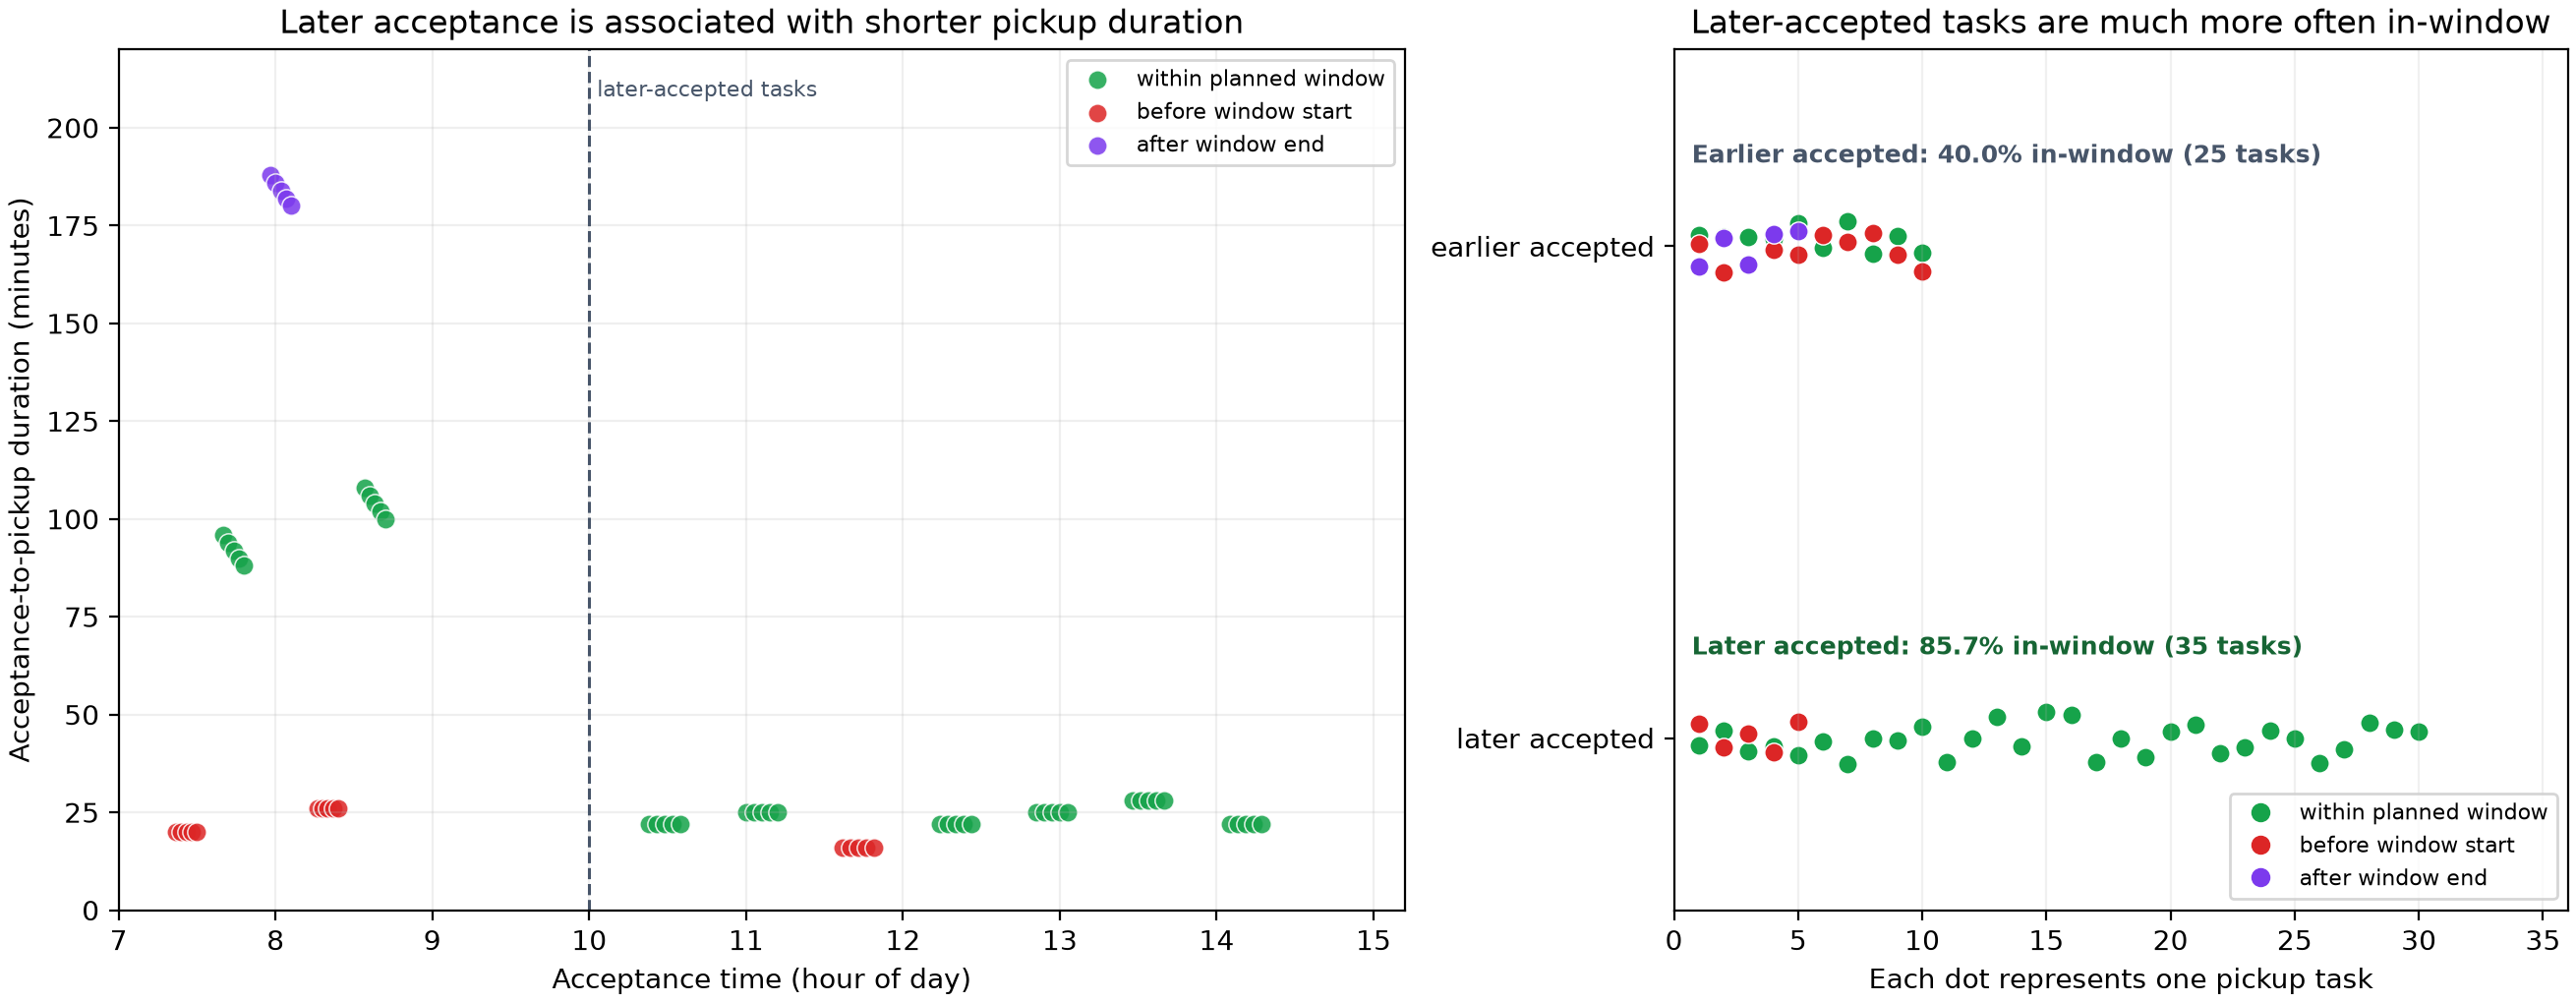

In [ ]:
import pandas as pd
tasks = pd.read_csv(dataset_path, parse_dates=['accept_time','time_window_start','time_window_end','pickup_time'])
# Compute pickup_time - accept_time and classify pickup_time as before, inside, or after [time_window_start, time_window_end]. Then compare earlier and later acceptance periods.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/acceptance_timing_duration_reliability.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "acceptance_time_duration_and_window_reliability",
  "insight": "Later-accepted pickup tasks are not only completed faster but are also more likely to fall within their promised service windows.",
  "insight_value": {
    "earlier_accepted_median_duration_min": 92,
    "later_accepted_median_duration_min": 22,
    "earlier_accepted_in_window_rate": "40%",
    "later_accepted_in_window_rate": "85.7%"
  },
  "plot": {
    "plot_type": "acceptance_time_duration_scatter_and_distribution",
    "title": "Acceptance Timing, Pickup Duration, and Window Reliability",
    "file": "visualizations/acceptance_timing_duration_reliability.png",
    "description": "Task-level acceptance times, actual pickup durations, and window outcomes show the faster, more reliable later-accepted group."
  },
  "question": "How do acceptance timing, actual pickup duration, and completion within the planned service window vary together across the pickup tasks?",
  "code": "import pandas as pd\ntasks = pd.read_csv(dataset_path, parse_dates=['accept_time','time_window_start','time_window_end','pickup_time'])\n# Compute pickup_time - accept_time and classify pickup_time as before, inside, or after [time_window_start, time_window_end]. Then compare earlier and later acceptance periods.",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### **Question 2**: Do the shortest pickup durations reliably indicate in-window service, or do rapid time-window violations also occur?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

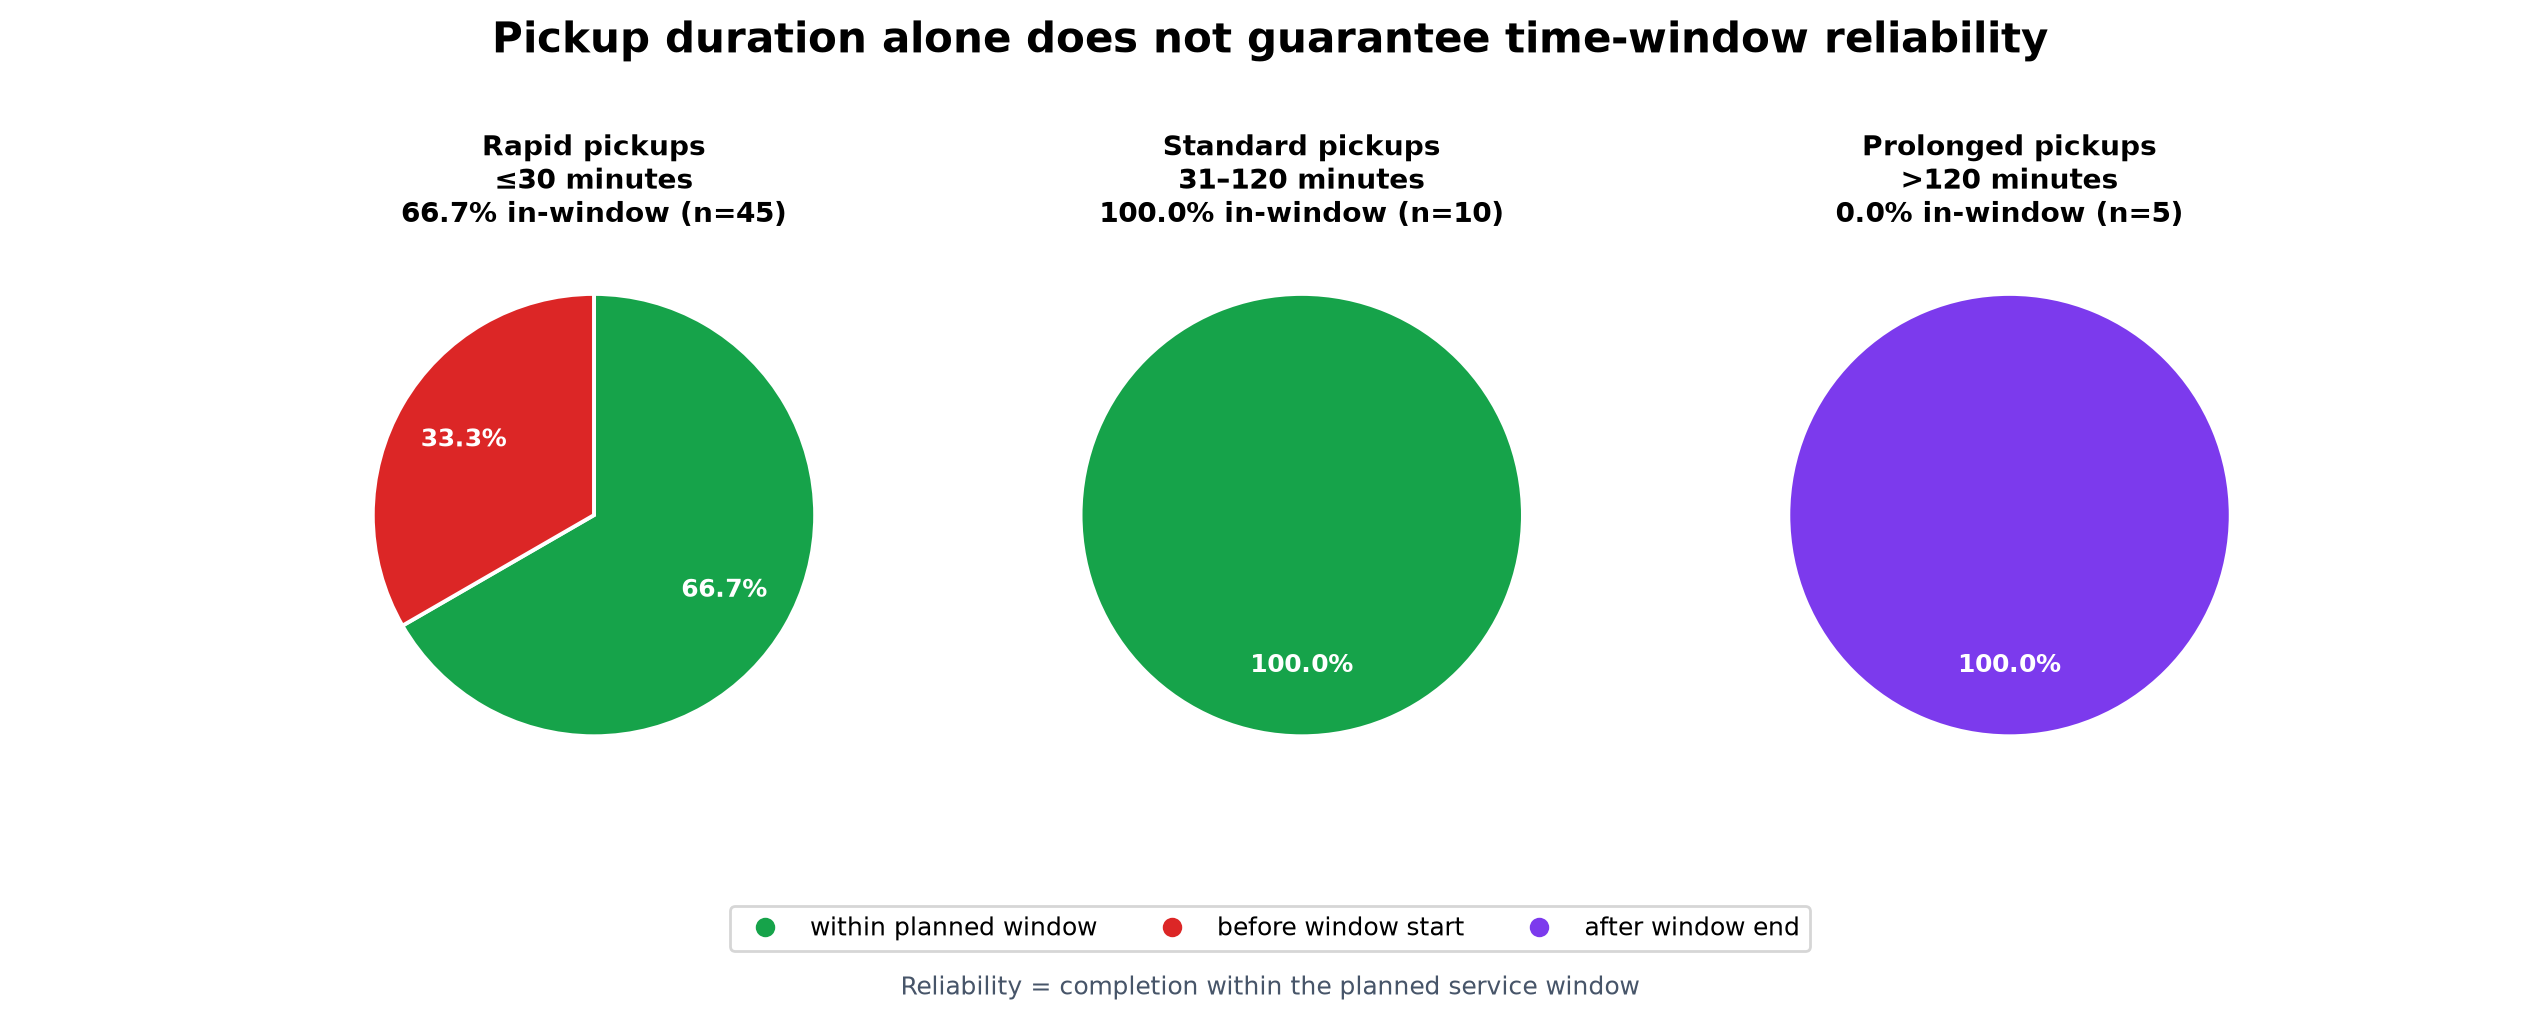

In [ ]:
import pandas as pd
tasks = pd.read_csv(dataset_path, parse_dates=['accept_time','time_window_start','time_window_end','pickup_time'])
# Compare acceptance-to-pickup durations for tasks completed before, within, and after their planned windows.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/rapid_pickup_window_outcomes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "rapid_completion_reliability_exception",
  "insight": "Short pickup durations do not necessarily correspond to higher reliability, as some rapidly completed tasks still violate their promised time windows.",
  "insight_value": {
    "rapid_threshold_min": 30,
    "rapid_task_count": 45,
    "rapid_in_window_rate": "66.7%",
    "rapid_early_window_violations": 15
  },
  "plot": {
    "plot_type": "duration_group_window_outcome_pies",
    "title": "Pickup Duration and Time-Window Reliability",
    "file": "visualizations/rapid_pickup_window_outcomes.png",
    "description": "Three duration-group pies show that 15 of 45 rapid pickups are early violations, whereas standard-duration pickups are all in-window in this sample."
  },
  "question": "Do the shortest pickup durations reliably indicate in-window service, or do rapid time-window violations also occur?",
  "code": "import pandas as pd\ntasks = pd.read_csv(dataset_path, parse_dates=['accept_time','time_window_start','time_window_end','pickup_time'])\n# Compare acceptance-to-pickup durations for tasks completed before, within, and after their planned windows.",
  "insight_type": "exception_deviation",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "accept_time",
    "pickup_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### **Question 3**: Among pickup tasks that violate the planned service window, are violations mainly early completions or delayed completions?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

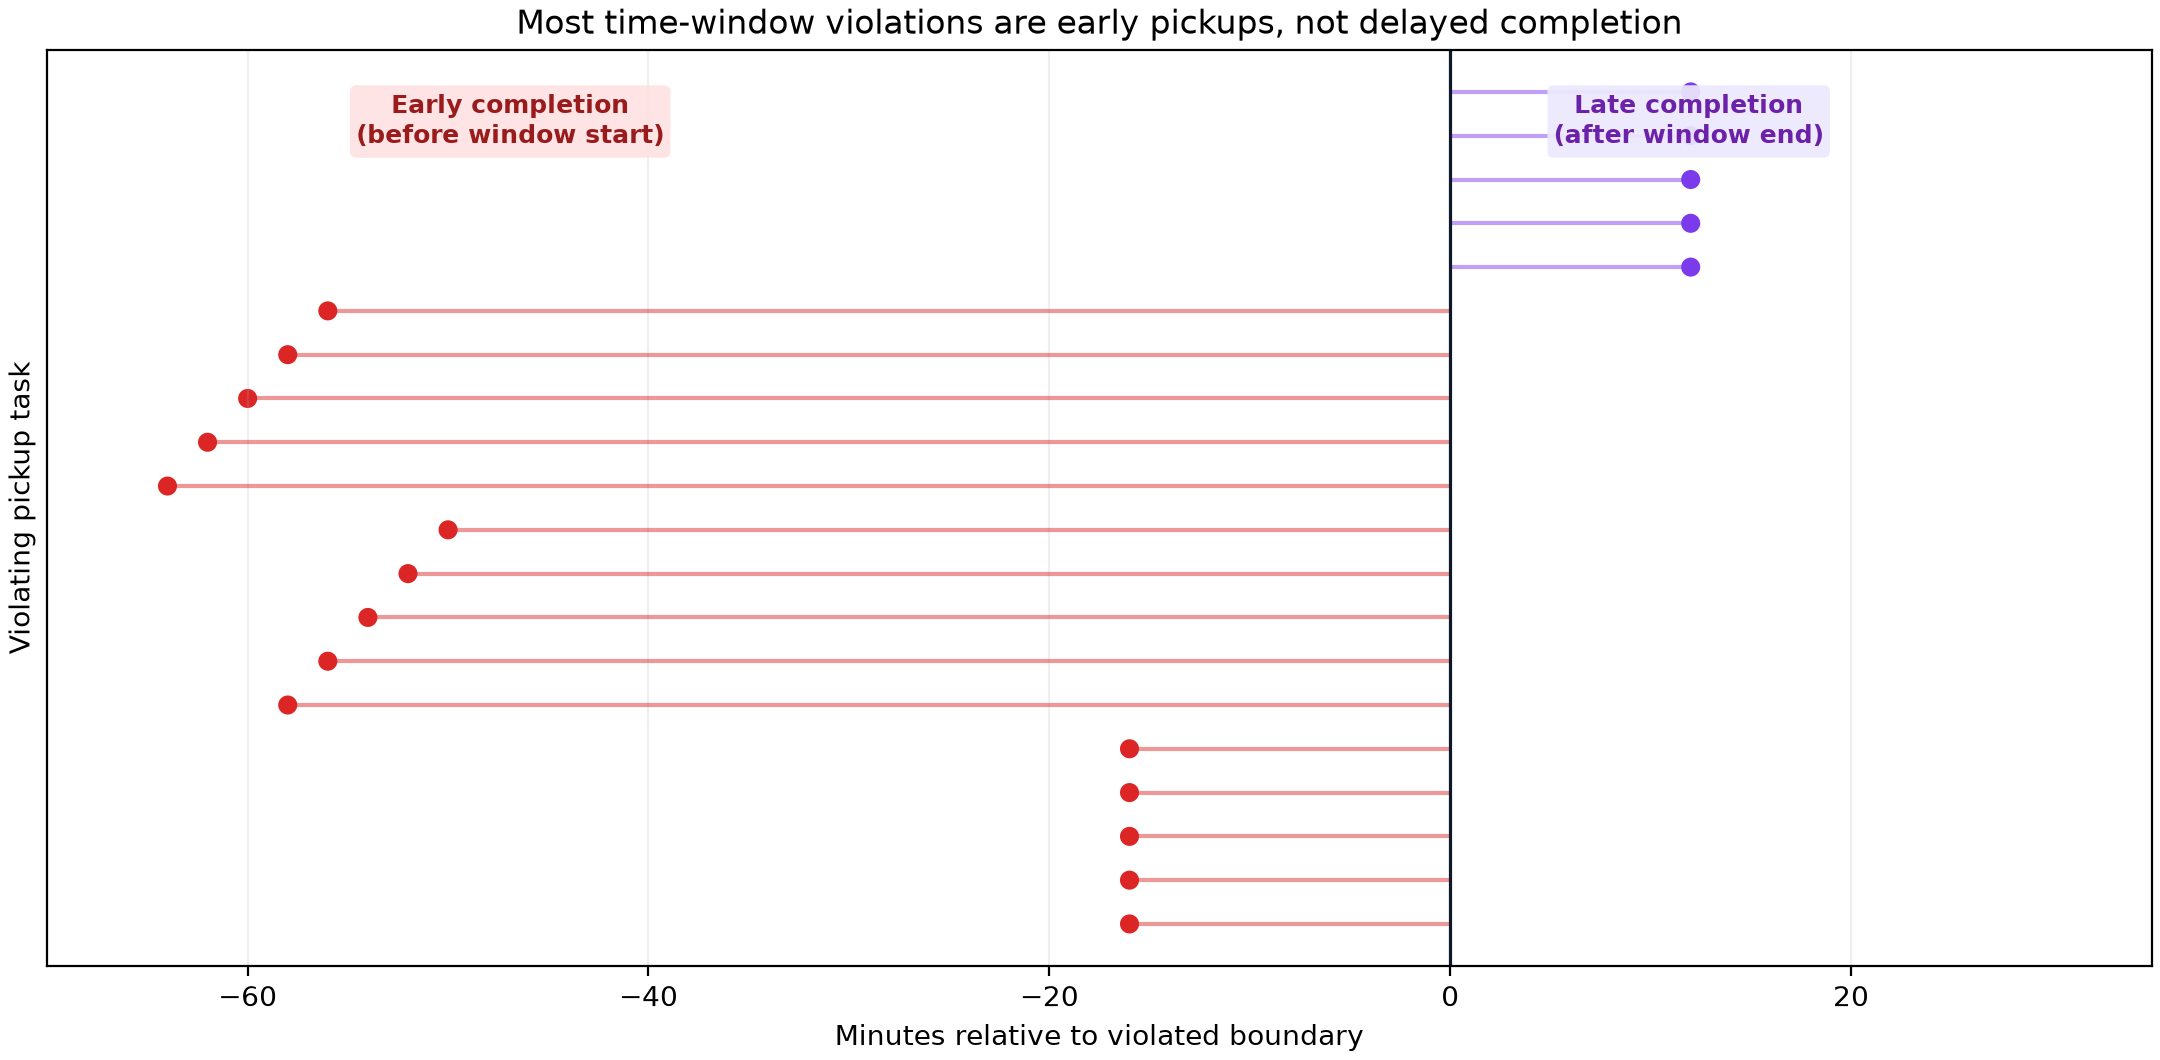

In [ ]:
import pandas as pd
tasks = pd.read_csv(dataset_path, parse_dates=['time_window_start','time_window_end','pickup_time'])
# Identify all outside-window pickups and count whether pickup_time is before time_window_start or after time_window_end.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/early_vs_late_window_violations.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "early_vs_late_time_window_violations",
  "insight": "Time-window violations are driven predominantly by pickups completed before the allowed window rather than by delayed completion.",
  "insight_value": {
    "early_violations": 15,
    "late_violations": 5,
    "early_violation_share": "75%"
  },
  "plot": {
    "plot_type": "signed_window_boundary_lollipop_plot",
    "title": "Early versus Late Time-Window Violations",
    "file": "visualizations/early_vs_late_window_violations.png",
    "description": "Negative values denote completion before a window begins; positive values denote completion after a window ends."
  },
  "question": "Among pickup tasks that violate the planned service window, are violations mainly early completions or delayed completions?",
  "code": "import pandas as pd\ntasks = pd.read_csv(dataset_path, parse_dates=['time_window_start','time_window_end','pickup_time'])\n# Identify all outside-window pickups and count whether pickup_time is before time_window_start or after time_window_end.",
  "insight_type": "factor_relationship",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "pickup_time",
    "time_window_start",
    "time_window_end",
    "task_id"
  ]
}

### **Question 4**: Where do pickups completed before their planned windows occur, and are these early completions spatially concentrated?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

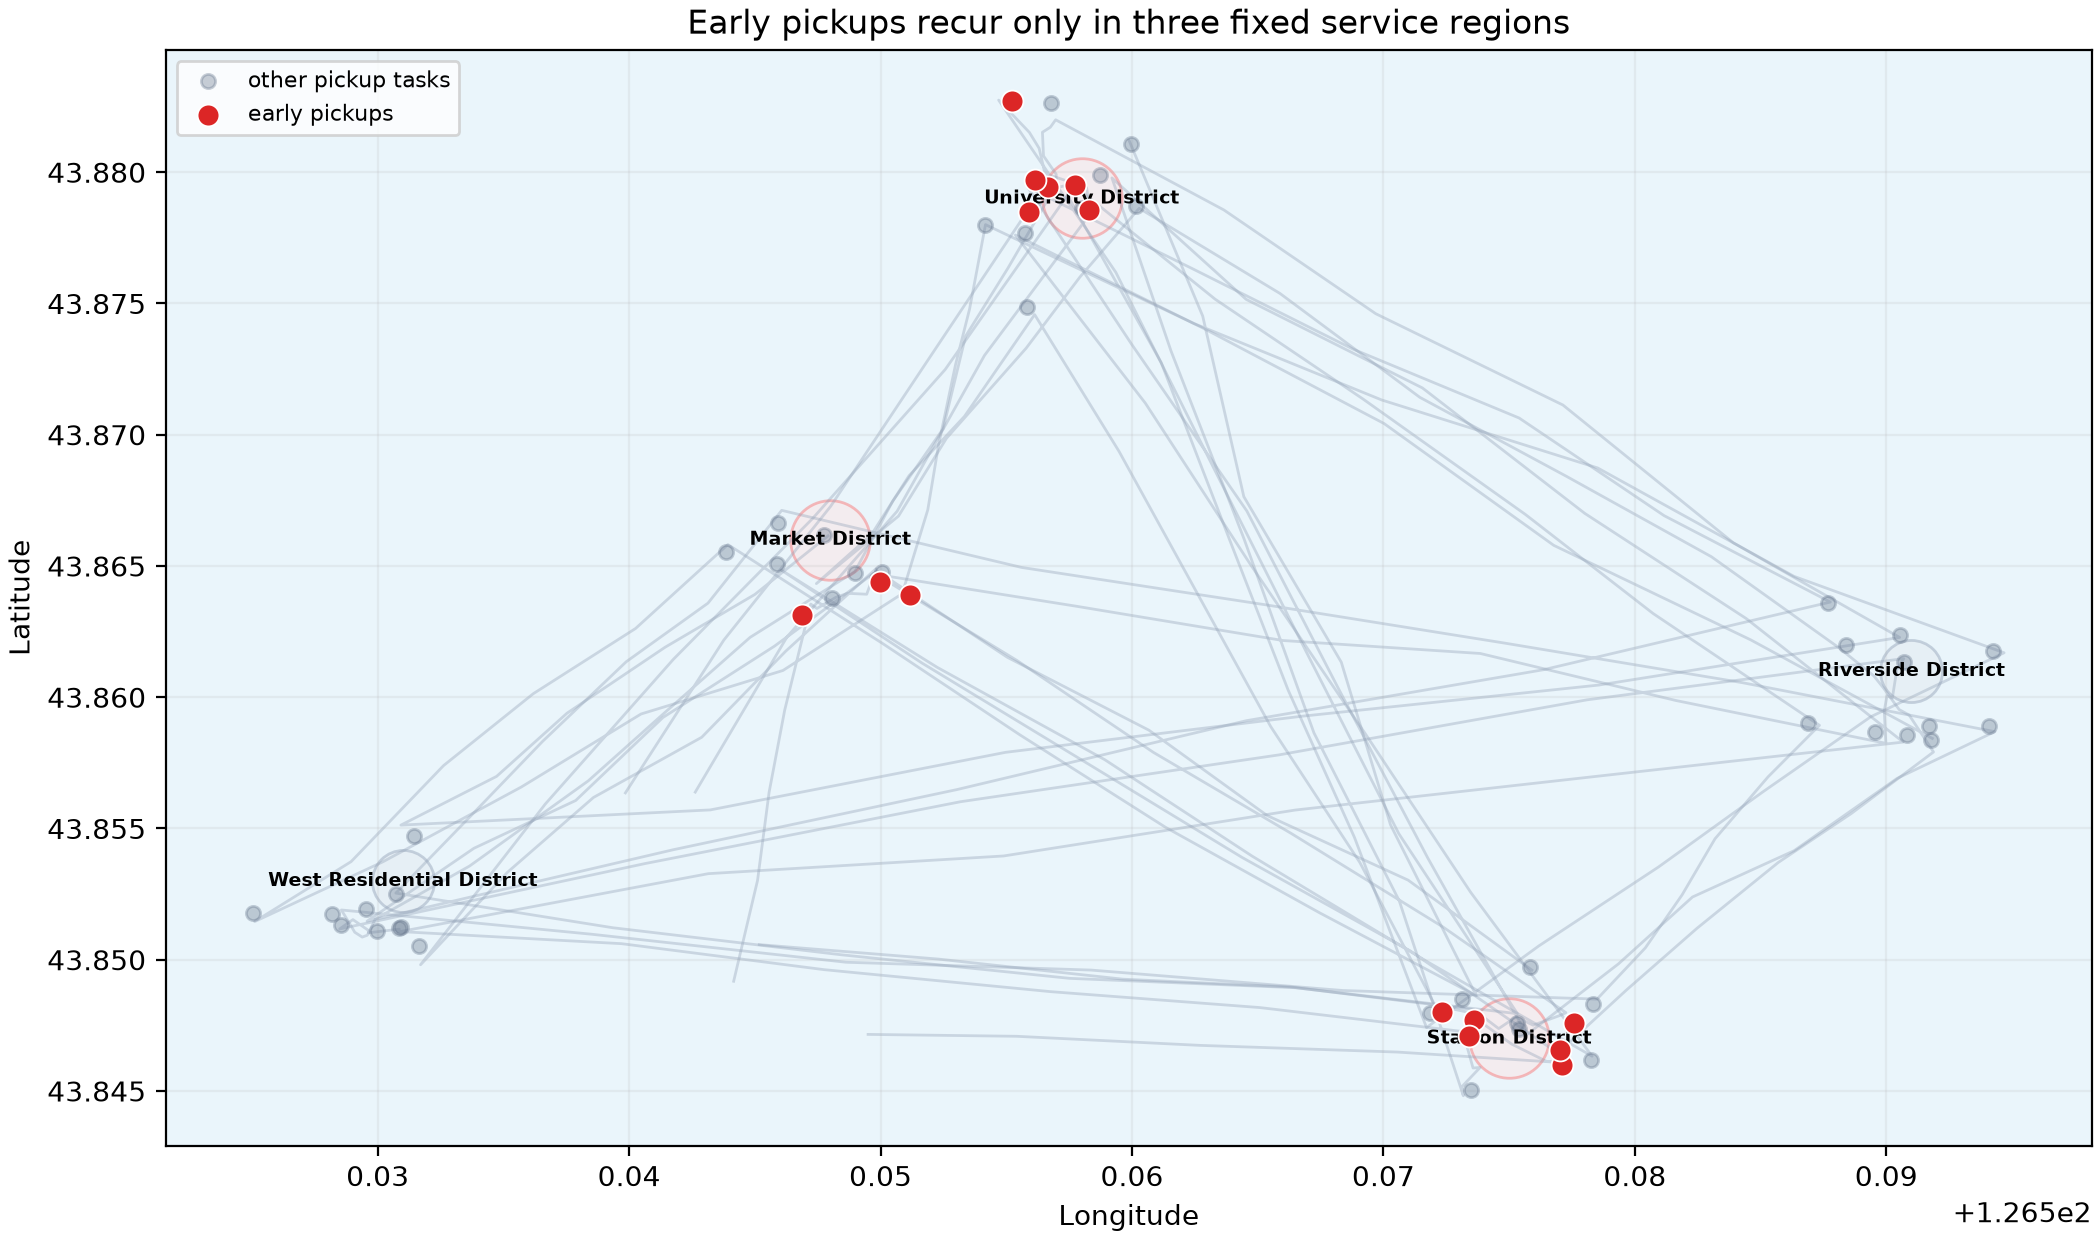

In [ ]:
import pandas as pd
tasks = pd.read_csv(dataset_path, parse_dates=['time_window_start','pickup_time'])
regions = pd.read_csv('regions.csv')
# Filter pickup_time < time_window_start, group by region_id, and map the filtered task coordinates with the courier trajectories.
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/early_pickup_regions_map.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "spatial_concentration_of_early_pickups",
  "insight": "Early pickups are spatially concentrated in a small set of recurring regions.",
  "insight_value": {
    "early_pickup_regions": [
      "Market District",
      "Station District",
      "University District"
    ],
    "early_pickup_region_count": 3
  },
  "plot": {
    "plot_type": "courier_trajectory_and_early_pickup_region_map",
    "title": "Fixed Regions of Early Pickup",
    "file": "visualizations/early_pickup_regions_map.png",
    "description": "Courier trajectories provide spatial context; every task completed before its allowed window is located in one of the three highlighted regions."
  },
  "question": "Where do pickups completed before their planned windows occur, and are these early completions spatially concentrated?",
  "code": "import pandas as pd\ntasks = pd.read_csv(dataset_path, parse_dates=['time_window_start','pickup_time'])\nregions = pd.read_csv('regions.csv')\n# Filter pickup_time < time_window_start, group by region_id, and map the filtered task coordinates with the courier trajectories.",
  "insight_type": "overall_pattern",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "pickup_time",
    "time_window_start",
    "task_position",
    "task_id",
    "gps_position",
    "courier_id"
  ]
}

### Summary of Findings (Flag 7)

Later-accepted pickup tasks in this multi-courier sample are generally shorter and more likely to be completed within their planned windows. However, rapid completion is not always reliable: most violations are early pickups, and all early pickups concentrate in three recurring service regions.